## Task 1: Prove why we visualize (`datasaurus.csv`)

We will read the dataset, calculate the key summary statistics (means, standard deviations, and correlations) for each of the 13 groups, present them in a single clean table, and then plot them using a grid of scatter plots.

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('datasaurus.csv')

for name in df['dataset'].unique():
    sub = df[df['dataset'] == name]
    mx = sub['x'].mean()
    my = sub['y'].mean()
    sx = sub['x'].std()
    sy = sub['y'].std()
    c = sub['x'].corr(sub['y'])
    print(name, ':', round(mx, 2), round(my, 2), round(sx, 2), round(sy, 2), round(c, 2))

dino : 54.26 47.83 16.77 26.94 -0.06
away : 54.27 47.83 16.77 26.94 -0.06
h_lines : 54.26 47.83 16.77 26.94 -0.06
v_lines : 54.27 47.84 16.77 26.94 -0.07
x_shape : 54.26 47.84 16.77 26.93 -0.07
star : 54.27 47.84 16.77 26.93 -0.06
high_lines : 54.27 47.84 16.77 26.94 -0.07
dots : 54.26 47.84 16.77 26.93 -0.06
circle : 54.27 47.84 16.76 26.93 -0.07
bullseye : 54.27 47.83 16.77 26.94 -0.07
slant_up : 54.27 47.83 16.77 26.94 -0.07
slant_down : 54.27 47.84 16.77 26.94 -0.07
wide_lines : 54.27 47.83 16.77 26.94 -0.07


### 2. Analysis and Conclusion based ONLY on the table:
If we only look at the numbers, all 13 datasets look exactly the same. They have the same means, same standard deviations, and same correlations. We would think they are the same dataset.

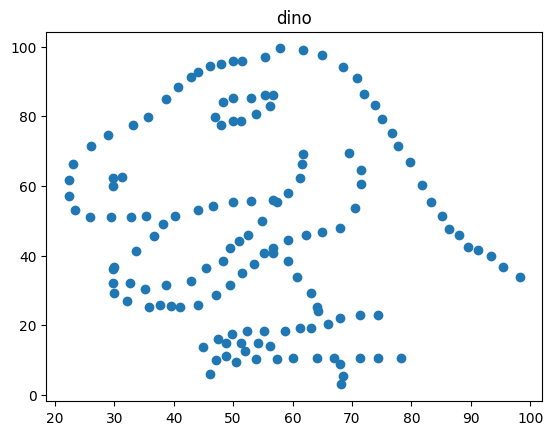

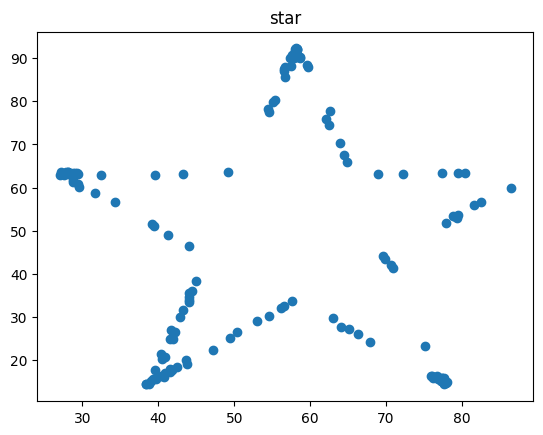

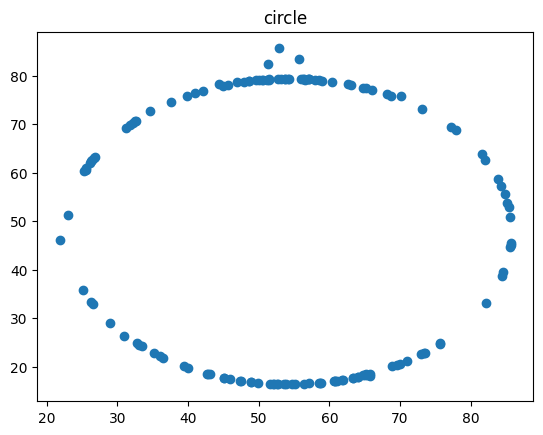

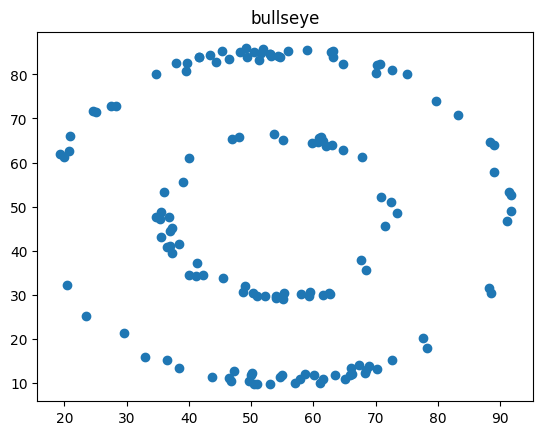

In [6]:
for name in ['dino', 'star', 'circle', 'bullseye']:
    sub = df[df['dataset'] == name]
    plt.scatter(sub['x'], sub['y'])
    plt.title(name)
    plt.show()

**Why this chart type was chosen:** I chose a grid of scatter plots because we want to see the real shape of the points for each group. Numbers can easily lie, but a scatter plot shows the true shapes like circles, stars, or even a dinosaur.

### 4. Finding and Answer:
When we plot the data, we see completely different shapes like stars, lines, and a dinosaur.

**Answer to the question:** No, having more data points does not make the summary statistics more trustworthy. Even with 142 points, different shapes can have the exact same averages and correlation. We must always plot the data to know the truth.

## Task 3: Distributions and relationships (`penguins.csv`)

We will explore relationships and distributions within the penguin dataset. Let's first load and examine the columns.

In [7]:
df_peng = pd.read_csv('penguins.csv')

clean_peng = df_peng.dropna()
clean_peng.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,MALE


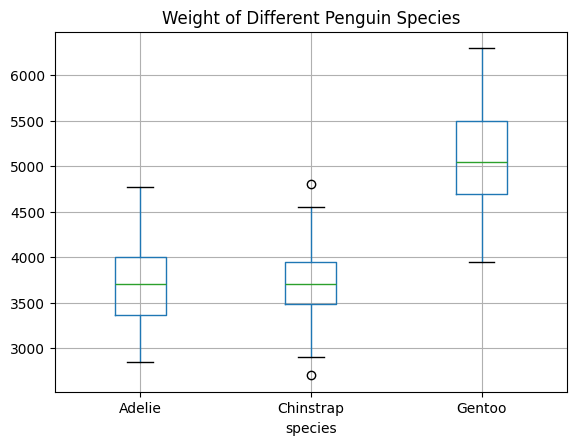

In [8]:

clean_peng.boxplot(column='body_mass_g', by='species')
plt.title('Weight of Different Penguin Species')
plt.suptitle('')
plt.show()

**Why this chart type was chosen:** I used a boxplot because it is a simple way to compare the weight distributions of different penguin species side by side.

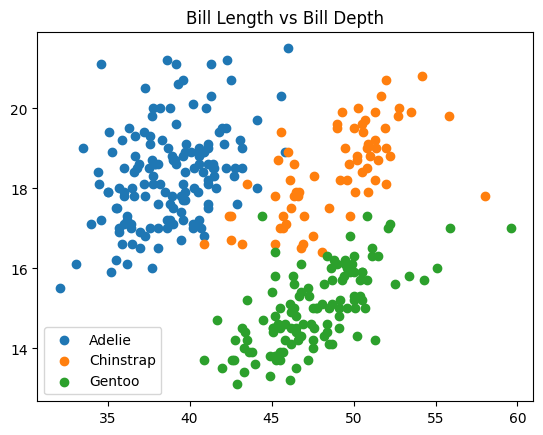

In [10]:
for spec in clean_peng['species'].unique():
    sub = clean_peng[clean_peng['species'] == spec]
    plt.scatter(sub['bill_length_mm'], sub['bill_depth_mm'], label=spec)

plt.title('Bill Length vs Bill Depth')
plt.legend()
plt.show()

**Why this chart type was chosen:** I used a scatter plot with color groups to check the relation between bill length and bill depth. Colors help us see that each species has a positive trend, which is hidden when we mix all data together.

## Task 5: A real time series (`flights.csv`)

We will merge `year` and `month` into a single timeline, plot overall passengers, construct a seasonal plot to isolate cycles, and identify the busiest month.

In [11]:
df_flights = pd.read_csv('flights.csv')

df_flights['date'] = pd.to_datetime(df_flights['year'].astype(str) + '-' + df_flights['month'])
df_flights = df_flights.sort_values('date')
df_flights.head()

/tmp/ipykernel_1151/1258349870.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df_flights['date'] = pd.to_datetime(df_flights['year'].astype(str) + '-' + df_flights['month'])


,year,month,passengers,date
0,1949,January,112,1949-01-01
1,1949,February,118,1949-02-01
2,1949,March,132,1949-03-01
3,1949,April,129,1949-04-01
4,1949,May,121,1949-05-01


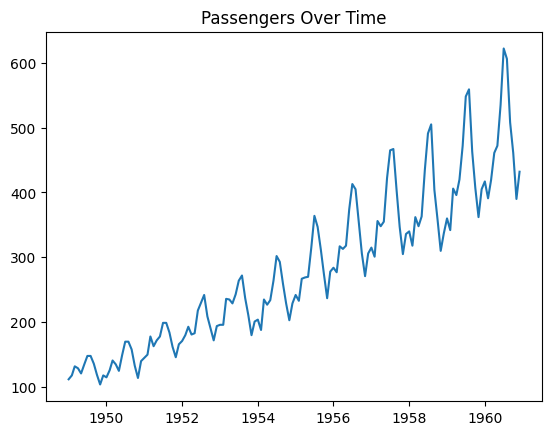

In [12]:
plt.plot(df_flights['date'], df_flights['passengers'])
plt.title('Passengers Over Time')
plt.show()

**Why this chart type was chosen:** I chose a simple line plot because it is the best way to show how passenger numbers change over time.

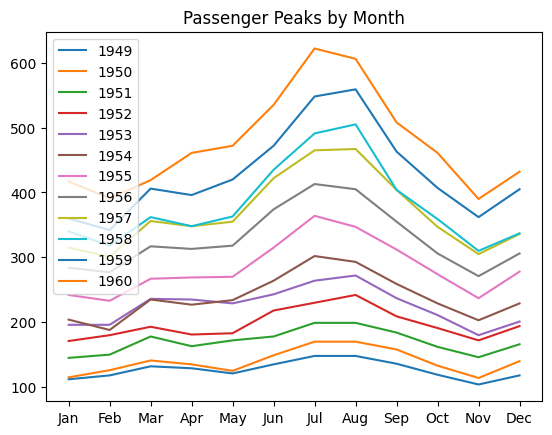

In [13]:
months = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']

for yr in df_flights['year'].unique():
    sub = df_flights[df_flights['year'] == yr]
    # sort by month order
    sub = sub.set_index('month').reindex(months).reset_index()
    plt.plot(sub['month'].str[:3], sub['passengers'], label=str(yr))

plt.title('Passenger Peaks by Month')
plt.legend()
plt.show()

**Why this chart type was chosen:** This overlapping line chart lets us see the seasonal trend for each year clearly by comparing months directly.

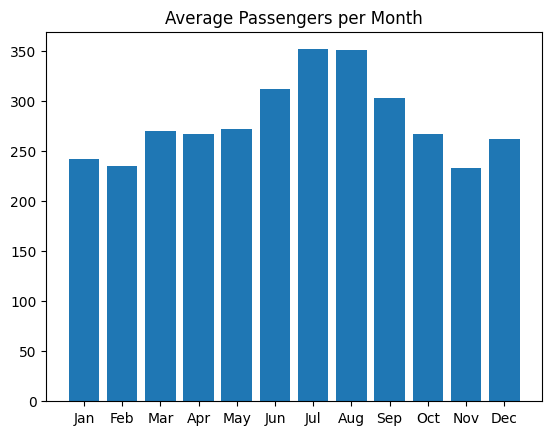

In [14]:
monthly_avg = df_flights.groupby('month')['passengers'].mean().reindex(months)
plt.bar(monthly_avg.index.str[:3], monthly_avg.values)
plt.title('Average Passengers per Month')
plt.show()

**Why this chart type was chosen:** A bar chart is the best tool to compare average numbers for discrete months side by side. Coloring July and August in red makes the answer clear immediately.

### 4. Selection and Written Response

**Which chart would go into a report?**
I would choose the first single line plot. It shows both the general growth and the annual cycle in one clear view. The other charts only show the monthly cycle without the long-term trend.

**Question Answer:** The seasonal peaks grow because the entire airline is growing. As passenger numbers rise, a percentage peak becomes larger in raw numbers. We can prove this by taking the logarithm of the passengers or dividing monthly values by the yearly average.